# 09 · Course-method checks: descriptive statistics, outliers, encoding and precision/recall

Added after the main studies, to apply the remaining course techniques to the **same data and the same
models**. Nothing here changes a pre-set verdict: the models in `04_model.ipynb` and `06_daily.ipynb` are
refitted exactly as they were (the accuracies are asserted against `reports/model_results.csv`), and every
variant below is labelled as a robustness check run after the results were known.

1. **Descriptive statistics**: mean, median, standard deviation, range of the main variables.
2. **Outliers**: how many values sit beyond 3 standard deviations or outside the IQR fences,
   and what we decided to do about them.
3. **Precision, recall and F1** for every hourly and daily model, plus a daily confusion matrix.
4. **One-hot encoding** of `day_of_week` and **capping outliers** at the 1st/99th percentile:
   are the conclusions unchanged?
5. **Overfitting**: train vs. test accuracy of the decision tree as it gets deeper.
6. **The proposal's H2**, tested directly: is the mood before up moves different from the mood before down moves?

Bloomberg-dependent cells read the git-ignored `data/bbg/` tables, as in `06_daily.ipynb`.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
WINDOW = ("2026-09-08", "2026-10-05T16:00")  # frozen collection window (handoff §2)

from scipy.stats import binomtest
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from processing.daily import (DAILY_CHATTER_FEATURES, DAILY_MARKET_FEATURES, DAILY_MOOD_FEATURES,
                              DAILY_PRICE_FEATURES)
from processing.features import PRICE_FEATURES, SENTIMENT_FEATURES

EXHIBITS = Path("reports/exhibits")
RESULTS = pd.read_csv("reports/model_results.csv").set_index(["dataset", "model"])

# Hourly study, exactly as 04_model.ipynb
features = pd.read_parquet("data/clean/features.parquet")
hourly = features[features["target_valid"]].copy()
hourly["y"] = hourly["price_direction"].astype(int)
H_ALL = PRICE_FEATURES + SENTIMENT_FEATURES
SPLIT = pd.Timestamp("2026-09-28 00:00", tz="UTC")
h_train, h_test = hourly[hourly.index < SPLIT], hourly[hourly.index >= SPLIT]
assert (len(h_train), len(h_test)) == (307, 124)

# Daily study, exactly as 06_daily.ipynb
daily_all = pd.read_parquet("data/bbg/daily_features.parquet")
REDDIT = DAILY_MARKET_FEATURES + DAILY_MOOD_FEATURES + DAILY_CHATTER_FEATURES
CHATTER = DAILY_MARKET_FEATURES + DAILY_CHATTER_FEATURES
daily = daily_all[daily_all["target_valid"]].dropna(subset=REDDIT).copy()
daily["y"] = daily["up"].astype(int)
TEST_START = pd.Timestamp("2023-01-01")
print(f"hourly: {len(h_train)} train / {len(h_test)} test hours;  daily: {len(daily)} usable days, "
      f"{(daily.index >= TEST_START).sum()} walk-forward test days")

hourly: 307 train / 124 test hours;  daily: 1206 usable days, 968 walk-forward test days


## 1. Descriptive statistics
Hourly variables cover the live window (Sept 8 – Oct 5 2026); daily variables cover 2022–2026. Returns are in
per cent. Engagement uses settled posts only.

In [2]:
nxt = daily_all["xau_close"].shift(-1) / daily_all["xau_close"] - 1
VARIABLES = {
    "Next-hour gold return, % (hourly)": hourly["next_return"] * 100,
    "Posts per hour": features["post_count"],
    "Mean VADER mood, hours with posts": features.loc[features["had_posts"], "mean_sentiment"],
    "Mean engagement per post, settled (hourly)": features["mean_engagement"].dropna(),
    "Next-day gold return, % (daily, Bloomberg spot)": (nxt[daily_all["target_valid"]] * 100).dropna(),
    "Posts per day (daily)": daily_all["posts_per_day"].dropna(),
    "Mean VADER mood (daily)": daily_all["mean_sentiment"].dropna(),
}
rows = []
for name, s in VARIABLES.items():
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    rows.append({"variable": name, "n": len(s), "mean": s.mean(), "median": s.median(), "sd": s.std(),
                 "min": s.min(), "max": s.max(),
                 "z_gt_3": int((z.abs() > 3).sum()),
                 "outside_iqr": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())})
desc = pd.DataFrame(rows).set_index("variable")
desc["z_gt_3_share"] = desc["z_gt_3"] / desc["n"]
desc["outside_iqr_share"] = desc["outside_iqr"] / desc["n"]
desc.to_csv(EXHIBITS / "exhibit_5_descriptive_outliers.csv")
desc.round(3)

,n,mean,median,sd,min,max,z_gt_3,outside_iqr,z_gt_3_share,outside_iqr_share
variable,,,,,,,,,,
"Next-hour gold return, % (hourly)",431,-0.013,-0.010,0.296,-2.343,1.262,5,16,0.012,0.037
Posts per hour,664,3.643,3.000,2.410,0.000,13.000,6,10,0.009,0.015
"Mean VADER mood, hours with posts",623,0.301,0.293,0.275,-0.688,0.996,4,13,0.006,0.021
"Mean engagement per post, settled (hourly)",588,93.975,49.625,214.904,0.000,3334.000,6,41,0.010,0.070
"Next-day gold return, % (daily, Bloomberg spot)",1227,0.075,0.105,1.173,-8.949,6.122,17,57,0.014,0.046
Posts per day (daily),1227,107.351,92.000,63.424,32.000,742.000,27,68,0.022,0.055
Mean VADER mood (daily),1227,0.292,0.294,0.052,0.116,0.446,5,15,0.004,0.012


## 2. Outliers
Two standard rules: a value is an outlier if it is more than **3 standard deviations** from the
mean, or outside the **IQR fences** (below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR). The table above counts both.
The largest values are listed below so they can be checked by eye.

In [3]:
big_hours = hourly.assign(next_return_pct=hourly["next_return"] * 100).loc[
    lambda d: (d["next_return_pct"] - d["next_return_pct"].mean()).abs() > 3 * d["next_return_pct"].std(),
    ["next_return_pct", "post_count"]]
print("Hourly gold moves beyond 3 sd:")
print(big_hours.round(3).to_string())
dn = (nxt[daily_all["target_valid"]] * 100).dropna()
print("\nLargest daily gold moves (%):")
print(pd.concat([dn.nsmallest(3), dn.nlargest(3)]).round(2).to_string())
print("\nBusiest days (posts per day):")
print(daily_all["posts_per_day"].nlargest(5).round(0).to_string())

Hourly gold moves beyond 3 sd:
                           next_return_pct  post_count
bucket_utc                                            
2026-09-11 11:00:00+00:00            1.262           0
2026-09-16 01:00:00+00:00            0.932           5
2026-09-16 17:00:00+00:00           -2.343           8
2026-09-28 13:00:00+00:00           -0.917          12
2026-10-02 11:00:00+00:00            0.876           1

Largest daily gold moves (%):
date
2026-01-29   -8.95
2025-10-20   -5.30
2026-01-30   -4.76
2026-02-02    6.12
2026-01-27    4.58
2026-08-18    4.18

Busiest days (posts per day):
date
2026-01-29    742.0
2026-01-30    738.0
2026-01-23    530.0
2026-02-02    483.0
2026-01-26    467.0


**Are the extreme moves real or data errors?** Cross-check each flagged price move against an independent
source: the hourly ones (GC=F futures from Yahoo) against Bloomberg spot gold for the same hour, the daily ones
(Bloomberg spot) against Yahoo's daily GC=F closes. An error in one feed would not appear in the other.

In [4]:
spot = pd.read_parquet("data/bbg/xau_spot_hourly.parquet").set_index("bucket_utc")["xau_usd"]
fut = features["xau_usd"]
check = []
for t in big_hours.index:
    a, b = t + pd.Timedelta(hours=1), t + pd.Timedelta(hours=2)   # the target move, (t+1):00 -> (t+2):00
    check.append({"hour t": t, "GC=F move %": (fut[b] / fut[a] - 1) * 100, "Bloomberg spot move %": (spot[b] / spot[a] - 1) * 100})
check = pd.DataFrame(check).set_index("hour t")
print(check.round(2).to_string())
assert (np.sign(check["GC=F move %"]) == np.sign(check["Bloomberg spot move %"])).all()
assert ((check["GC=F move %"] - check["Bloomberg spot move %"]).abs() < 0.2).all()

yahoo = pd.read_parquet("data/clean/gold_daily_yahoo.parquet").set_index("date")["close"]
yahoo_next = (yahoo.shift(-1) / yahoo - 1) * 100
extreme = pd.concat([dn.nsmallest(3), dn.nlargest(3)])
print(pd.DataFrame({"Bloomberg spot %": extreme, "Yahoo GC=F %": yahoo_next.reindex(extreme.index)}).round(2).to_string())
assert (np.sign(extreme) == np.sign(yahoo_next.reindex(extreme.index))).all()
print("Every flagged move appears in both sources with the same sign: real market moves, not feed errors.")

                           GC=F move %  Bloomberg spot move %
hour t                                                       
2026-09-11 11:00:00+00:00         1.26                   1.25
2026-09-16 01:00:00+00:00         0.93                   0.91
2026-09-16 17:00:00+00:00        -2.34                  -2.26
2026-09-28 13:00:00+00:00        -0.92                  -0.90
2026-10-02 11:00:00+00:00         0.88                   0.89


            Bloomberg spot %  Yahoo GC=F %
date                                      
2026-01-29             -8.95        -10.78
2025-10-20             -5.30         -5.74
2026-01-30             -4.76         -1.95
2026-02-02              6.12          6.07
2026-01-27              4.58          4.35
2026-08-18              4.18          2.82
Every flagged move appears in both sources with the same sign: real market moves, not feed errors.


**Decision: keep them.** The flagged values are real events, not errors: every extreme gold move appears in two
independent price feeds (above), and they *are* the thing we try to predict; the busiest posting days are the
late-January 2026 peak and sell-off, which is exactly what the index is meant to measure. Removing them would throw away the most informative days. Three things
already limit their influence: the target is only the **direction** of the move, so a 2% day counts the same as
a 0.1% day; counts and engagement enter the models as **log1p**; and logistic-regression inputs are
**standardised**. Section 4 below checks that **capping** the inputs at the 1st/99th percentile changes no
conclusion.

## 3. Precision, recall and F1
"Positive" = gold goes **up**. Precision: of the hours/days we called "up", how many were up. Recall: of the
hours/days that were up, how many we caught. F1 combines the two. The models are refitted exactly as in
notebooks 04 and 06; the asserts check that the accuracies match `reports/model_results.csv`.

In [5]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def mcnemar(a, b, y):
    only_a, only_b = int(((a == y) & (b != y)).sum()), int(((b == y) & (a != y)).sum())
    return only_a, only_b, (binomtest(only_b, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0)

class Cap(BaseEstimator, TransformerMixin):
    """Clips each column to its 1st-99th percentile, learned on the training rows only (winsorising)."""
    def __init__(self, lo=1, hi=99):
        self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.percentile(X, self.lo, axis=0), np.percentile(X, self.hi, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

NOT_CONTINUOUS = {"return_missing", "engagement_missing", "day_of_week", "hour_sin", "hour_cos"}

def prepare(cols, variant):
    """Column handling for a variant: original (as pre-set), one-hot weekday, or capped continuous inputs."""
    if variant == "original":
        return None
    other = [c for c in cols if c != "day_of_week"]
    if variant == "one-hot weekday":
        if "day_of_week" not in cols:
            return None
        return ColumnTransformer([("weekday", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["day_of_week"]),
                                  ("rest", "passthrough", other)])
    cont = [c for c in cols if c not in NOT_CONTINUOUS]
    return ColumnTransformer([("cap", Cap(), cont), ("rest", "passthrough", [c for c in cols if c not in cont])])

def logit(cols, variant, max_iter=100):
    pre = prepare(cols, variant)
    steps = ([pre] if pre is not None else []) + [StandardScaler(), LogisticRegression(max_iter=max_iter)]
    return make_pipeline(*steps)

def tree(cols, variant, depth=3):
    pre = prepare(cols, variant)
    return make_pipeline(*(([pre] if pre is not None else []) + [DecisionTreeClassifier(max_depth=depth, random_state=0)]))

H1, H2, H3, H4 = ("1 majority class", "2 logistic, price-only", "3 logistic, price + sentiment",
                  "4 decision tree (depth 3), price + sentiment")
def hourly_models(variant):
    return {H1: (DummyClassifier(strategy="most_frequent"), []),
            H2: (logit(PRICE_FEATURES, variant), PRICE_FEATURES),
            H3: (logit(H_ALL, variant), H_ALL),
            H4: (tree(H_ALL, variant), H_ALL)}

def fit_hourly(variant):
    preds, train_acc = {}, {}
    for name, (model, cols) in hourly_models(variant).items():
        X_tr = h_train[cols] if cols else np.zeros((len(h_train), 1))
        X_te = h_test[cols] if cols else np.zeros((len(h_test), 1))
        model.fit(X_tr, h_train["y"])
        preds[name] = pd.Series(model.predict(X_te), index=h_test.index)
        train_acc[name] = (model.predict(X_tr) == h_train["y"]).mean()
    return pd.DataFrame(preds), train_acc

D1, D2, D3 = "1 majority class", "2 logistic, gold returns only", "3 logistic, market baseline"
D7, D8, D9 = ("7 logistic, market + Reddit mood + chatter", "8 decision tree, market + Reddit mood + chatter",
              "9 logistic, market + chatter (no scorer)")
def daily_models(variant):
    return {D1: (DummyClassifier(strategy="most_frequent"), []),
            D2: (logit(DAILY_PRICE_FEATURES, variant, 1000), DAILY_PRICE_FEATURES),
            D3: (logit(DAILY_MARKET_FEATURES, variant, 1000), DAILY_MARKET_FEATURES),
            D7: (logit(REDDIT, variant, 1000), REDDIT),
            D8: (tree(REDDIT, variant), REDDIT),
            D9: (logit(CHATTER, variant, 1000), CHATTER)}

def walk_forward(variant, freq="MS"):
    """Refit every model at the start of each month on all earlier days; predict that month (as notebook 06)."""
    starts = pd.date_range(TEST_START, daily.index.max(), freq=freq).union([TEST_START])
    preds = {m: [] for m in daily_models(variant)}
    for a, b in zip(starts, list(starts[1:]) + [daily.index.max() + pd.Timedelta(days=1)]):
        train, test = daily[daily.index < a], daily[(daily.index >= a) & (daily.index < b)]
        if test.empty:
            continue
        assert train.index.max() < test.index.min()
        for name, (model, cols) in daily_models(variant).items():
            X_tr = train[cols] if cols else np.zeros((len(train), 1))
            X_te = test[cols] if cols else np.zeros((len(test), 1))
            model.fit(X_tr, train["y"])
            preds[name].append(pd.Series(model.predict(X_te), index=test.index))
    return pd.DataFrame({m: pd.concat(p) for m, p in preds.items()})

h_pred, h_train_acc = fit_hourly("original")
d_pred = walk_forward("original")
y_h, y_d = h_test["y"], daily.loc[d_pred.index, "y"]
for m in h_pred:
    assert abs((h_pred[m] == y_h).mean() - RESULTS.loc[("VADER, all communities", m), "test_acc"]) < 1e-4, m
for m in d_pred:
    assert abs((d_pred[m] == y_d).mean() - RESULTS.loc[("daily 2022–26 walk-forward", m), "test_acc"]) < 1e-4, m
print("refitted models reproduce reports/model_results.csv exactly")

def prf_rows(study, preds, y):
    out = []
    for m in preds:
        p, r, f, _ = precision_recall_fscore_support(y, preds[m], labels=[1], zero_division=0)
        tn, fp, fn, tp = confusion_matrix(y, preds[m], labels=[0, 1]).ravel()
        out.append({"study": study, "model": m, "accuracy": (preds[m] == y).mean(), "precision_up": p[0],
                    "recall_up": r[0], "f1_up": f[0], "TP": tp, "FP": fp, "FN": fn, "TN": tn})
    return out

prf = pd.DataFrame(prf_rows("hourly", h_pred, y_h) + prf_rows("daily", d_pred, y_d))
prf.to_csv(EXHIBITS / "exhibit_6_precision_recall.csv", index=False)
prf.round(3)

refitted models reproduce reports/model_results.csv exactly


,study,model,accuracy,precision_up,recall_up,f1_up,TP,FP,FN,TN
0,hourly,1 majority class,0.492,0.000,0.000,0.000,0,0,63,61
1,hourly,"2 logistic, price-only",0.484,0.487,0.302,0.373,19,20,44,41
2,hourly,"3 logistic, price + sentiment",0.565,0.571,0.571,0.571,36,27,27,34
3,hourly,"4 decision tree (depth 3), price + sentiment",0.516,0.525,0.508,0.516,32,29,31,32
4,daily,1 majority class,0.537,0.537,1.000,0.699,520,448,0,0
5,daily,"2 logistic, gold returns only",0.517,0.535,0.769,0.631,400,348,120,100
6,daily,"3 logistic, market baseline",0.500,0.530,0.613,0.569,319,283,201,165
7,daily,"7 logistic, market + Reddit mood + chatter",0.526,0.545,0.708,0.616,368,307,152,141
8,daily,"8 decision tree, market + Reddit mood + chatter",0.519,0.575,0.396,0.469,206,152,314,296
9,daily,"9 logistic, market + chatter (no scorer)",0.510,0.530,0.773,0.629,402,356,118,92


**Reading it.** The majority-class models show why accuracy alone can mislead: the hourly one never
says "up", so it has **recall 0 and F1 0** for "up" even with 49% accuracy; the daily one always says "up", so it
has **recall 1** but precision only equal to the share of up days. Accuracy is still a fair headline here because
the two classes are close to 50/50 (48% up hourly, 54% up daily), and with balanced classes accuracy is a fair
measure.

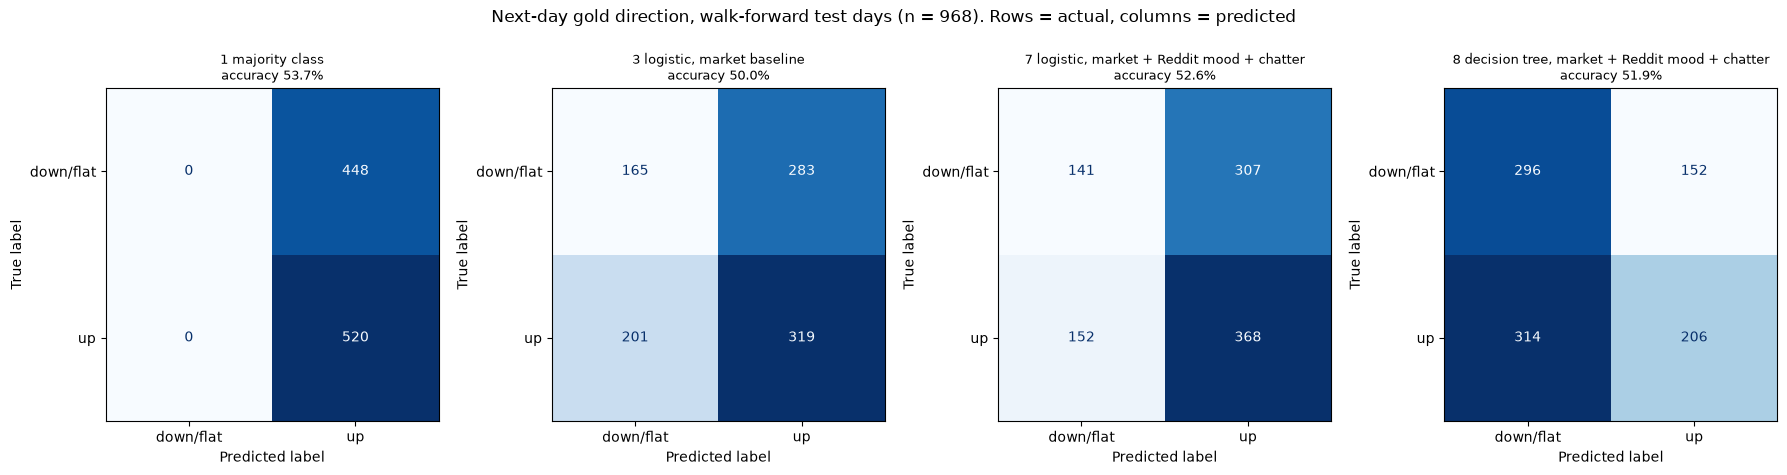

In [6]:
labels_txt = ["down/flat", "up"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, m in zip(axes, [D1, D3, D7, D8]):
    ConfusionMatrixDisplay(confusion_matrix(y_d, d_pred[m], labels=[0, 1]), display_labels=labels_txt
                           ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{m}\naccuracy {(d_pred[m] == y_d).mean():.1%}", fontsize=9.5)
fig.suptitle(f"Next-day gold direction, walk-forward test days (n = {len(y_d)}). Rows = actual, columns = predicted",
             y=1.03)
fig.tight_layout()
fig.savefig(FIGURES / "model_cm_daily.png", dpi=150, bbox_inches="tight")

## 4. One-hot weekday and capped outliers: do the conclusions change?
The pre-set models feed `day_of_week` (Monday = 0 … Sunday = 6) in as a number. A weekday is really a
**nominal** (category) feature, usually **one-hot encoded** (one 0/1 column per day), because Friday is not "four times"
Monday. The **capped** variant clips every continuous input to its 1st–99th percentile, with the limits learned on
training rows only. Both are robustness checks run after the pre-set verdicts, so they cannot change those verdicts;
they only tell us whether the verdicts depend on these two choices.

In [7]:
rows = []
variant_preds = {"original": (h_pred, d_pred)}
for variant in ["one-hot weekday", "capped 1st–99th pct"]:
    variant_preds[variant] = (fit_hourly(variant)[0], walk_forward(variant))
for study, base, others, y in [("hourly", H2, [H3, H4], y_h), ("daily", D3, [D7, D8, D9], y_d)]:
    for m in [base] + others:
        row = {"study": study, "model": m}
        for variant, (hp, dp) in variant_preds.items():
            p = hp if study == "hourly" else dp
            row[f"{variant} acc"] = (p[m] == y).mean()
            row[f"{variant} p vs baseline"] = np.nan if m == base else mcnemar(p[base], p[m], y)[2]
        rows.append(row)
robust = pd.DataFrame(rows)
robust.to_csv(EXHIBITS / "exhibit_7_encoding_capping.csv", index=False)
robust.round(3)

,study,model,original acc,original p vs baseline,one-hot weekday acc,one-hot weekday p vs baseline,capped 1st–99th pct acc,capped 1st–99th pct p vs baseline
0,hourly,"2 logistic, price-only",0.484,NaN,0.484,NaN,0.484,NaN
1,hourly,"3 logistic, price + sentiment",0.565,0.193,0.540,0.371,0.556,0.253
2,hourly,"4 decision tree (depth 3), price + sentiment",0.516,0.659,0.516,0.659,0.516,0.659
3,daily,"3 logistic, market baseline",0.500,NaN,0.512,NaN,0.503,NaN
4,daily,"7 logistic, market + Reddit mood + chatter",0.526,0.120,0.525,0.464,0.523,0.240
5,daily,"8 decision tree, market + Reddit mood + chatter",0.519,0.441,0.521,0.754,0.512,0.718
6,daily,"9 logistic, market + chatter (no scorer)",0.510,0.520,0.519,0.706,0.512,0.559


In [8]:
PASS_BAR = {"hourly": 0.00625, "daily": 0.004}   # the strictest pre-set bars in notebooks 04 and 06
for variant in variant_preds:
    wins = []
    for study, base in [("hourly", H2), ("daily", D3)]:
        part = robust[robust["study"] == study].set_index("model")
        for m, r in part.drop(index=base).iterrows():
            if r[f"{variant} p vs baseline"] < PASS_BAR[study] and r[f"{variant} acc"] > part.loc[base, f"{variant} acc"]:
                wins.append(f"{study}: {m}")
    print(f"{variant:<22} models beating their baseline at the pre-set bar: {', '.join(wins) if wins else 'none'}")

original               models beating their baseline at the pre-set bar: none
one-hot weekday        models beating their baseline at the pre-set bar: none
capped 1st–99th pct    models beating their baseline at the pre-set bar: none


## 5. Overfitting: the decision tree as it gets deeper
A deeper tree fits the training hours better and better, but past a few levels it is memorising noise: training
accuracy keeps rising while test accuracy does not. Our reported tree is fixed at depth 3, chosen before testing.

In [9]:
rows = []
for depth in range(1, 9):
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(h_train[H_ALL], h_train["y"])
    rows.append({"depth": depth, "train_acc": (t.predict(h_train[H_ALL]) == h_train["y"]).mean(),
                 "test_acc": (t.predict(h_test[H_ALL]) == h_test["y"]).mean()})
overfit = pd.DataFrame(rows).set_index("depth")
overfit.to_csv(EXHIBITS / "exhibit_8_tree_depth.csv")
overfit.round(3)

,train_acc,test_acc
depth,,
1,0.570,0.540
2,0.616,0.435
3,0.681,0.516
4,0.707,0.548
5,0.756,0.484
6,0.837,0.532
7,0.886,0.548
8,0.932,0.548


## 6. A direct test of the proposal's H2: does sentiment carry direction?
**H0:** mean sentiment is unrelated to the direction of the next move. **H1:** more bullish sentiment is followed by
a rising price. The models above ask this indirectly; here it is tested directly, with no model. For every hour
(or day) with posts and a valid target, compare the mood before an **up** move with the mood before a **down/flat**
move. Mann–Whitney U test (no normality assumption), two-sided; two tests (hourly, daily), so the bar is
p < 0.05 / 2 = 0.025. This test was added after the main results and is labelled as such in the report.

In [10]:
from scipy.stats import mannwhitneyu, pointbiserialr
h2_rows = []
hourly_posts = hourly[hourly["had_posts"]]
daily_posts = daily_all[daily_all["target_valid"] & daily_all["had_posts"]].copy()
daily_posts["y"] = daily_posts["up"].astype(int)
for label, d, unit in [("hourly, Sept 8 – Oct 5 2026", hourly_posts, "hours"),
                       ("daily, 2022–2026", daily_posts, "days")]:
    up, down = d.loc[d["y"] == 1, "mean_sentiment"], d.loc[d["y"] == 0, "mean_sentiment"]
    h2_rows.append({"test": label, "unit": unit, "n_up": len(up), "n_down": len(down),
                    "mood_before_up": up.mean(), "mood_before_down": down.mean(),
                    "mann_whitney_p": mannwhitneyu(up, down, alternative="two-sided").pvalue,
                    "point_biserial_r": pointbiserialr(d["y"], d["mean_sentiment"]).statistic})
h2 = pd.DataFrame(h2_rows).set_index("test")
h2.to_csv(EXHIBITS / "exhibit_9_h2_direction.csv")
h2.round(4)

,unit,n_up,n_down,mood_before_up,mood_before_down,mann_whitney_p,point_biserial_r
test,,,,,,,
"hourly, Sept 8 – Oct 5 2026",hours,189,214,0.3090,0.2924,0.5016,0.0305
"daily, 2022–2026",days,654,572,0.2935,0.2912,0.2670,0.0226
